# CS505 — Predictive Maintenance of Industrial Bearings Using NASA IMS Vibration Data

**Course:** CS505 Data Mining  
**Project:** Comparative analysis of bearing vibration features and unsupervised anomaly-detection methods  
**Dataset:** [NASA IMS Bearings — University of Cincinnati](https://data.nasa.gov/dataset/ims-bearings)  
**Team:** Four members (replace placeholders with actual names)

### Team contributions

| Contributor | Assigned sections | Main contribution |
|---|---|---|
| Lead Researcher — **name** | Introduction & Related Work | Background research, motivation, significance, research question, and literature review |
| Maruthi Jampani | 1–6 | Shared Drive setup, data inspection, preprocessing, vibration feature engineering, and exploratory analysis |
| Clayton Jace Roy | 7 | Experimental design, Isolation Forest, and PCA reconstruction-error anomaly models |
| Aven Pacha Pinto | 8–9 | Anomaly-score visualization and descriptive model comparison |
| Member 5 — **name** | 10 | Experiment settings, reproducibility documentation, and saved experimental artifacts |
| Member 6 — **name** | 11 | Interpretation, strengths and limitations, abstract, conclusions, and integration review |

Each contributor is also responsible for completing their corresponding sections of the shared report, IEEE references, PowerPoint slides, and individual recorded presentation segment.

## Project introduction
Industrial rolling bearings can exhibit changes in vibration behavior as mechanical conditions deteriorate. The IMS dataset contains sequential vibration recordings from bearing test rigs. We examine whether engineered time-domain and frequency-domain features reveal changes over the course of each recorded run.

**Research question:** How do Isolation Forest and PCA reconstruction-error methods characterize changes in bearing vibration patterns when trained on an early-run reference period?

**Scope:** This is an **unsupervised anomaly-monitoring study**. An anomaly score is not a verified fault label, and this notebook does **not** estimate remaining useful life or claim early-warning lead time. The original data and provenance must be cited in the final paper.

### Workflow
Original NASA recordings → validate files → compute per-channel vibration features → visualize trends → fit reference-period anomaly models → compare score and alert patterns → save reproducible artifacts.


## 1. Connect Google Drive and initialize the environment — Maruthi Jampani

**Objective:** Establish a consistent Google Colab environment and shared Google Drive directory structure for processing the NASA IMS bearing vibration dataset. This setup allows team members to access the same source recordings, processed features, and generated results while working in separate Colab runtimes.

**First-time setup:**
1. Create `CS505_Predictive_Maintenance_Project` in Google Drive and share it with the team using Editor access.
2. Place this notebook in the project root (no separate notebook folder).
3. Create `data/raw`, `data/processed`, `models`, and `results/figures`, or let the code create them.
4. Each teammate must mount Google Drive in **their own Colab runtime**; a shared folder is not a shared execution environment.

**Execution:** Run the package-install cell, then authorize the Drive mount. If the project is shared through a shortcut, verify that `ROOT` points to the shortcut's location under **My Drive**.

**Expected output:** The project path and the names of any ZIP files currently present in `data/raw`.

**Reproducibility:** Random seed 42 is set for the experiment. Keep the directory layout consistent across members.


In [ ]:
%pip -q install numpy pandas scipy scikit-learn matplotlib seaborn joblib tqdm

In [ ]:
# Section 1: Connect Google Drive and initialize the environment

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import os
import re
import json
import zipfile
import hashlib
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import kurtosis, skew
from scipy.signal import welch

from sklearn.preprocessing import RobustScaler
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score

import joblib
from tqdm.auto import tqdm

# Reproducibility
SEED = 42
np.random.seed(SEED)

# Shared Google Drive project folder
ROOT = Path(
    '/content/drive/MyDrive/CS505_Predictive_Maintenance_Project'
)

# Verify the project folder exists before creating subfolders
if not ROOT.is_dir():
    raise FileNotFoundError(
        f"Project folder not found: {ROOT}\n"
        "Please add the shared project folder shortcut to My Drive "
        "and verify the folder name."
    )

print("Shared project folder found:", ROOT)

# Project directory structure
RAW = ROOT / 'data' / 'raw'
EXTRACT = RAW / 'extracted'
CACHE = ROOT / 'data' / 'processed'
MODELS = ROOT / 'models'
RESULTS = ROOT / 'results'
FIGURES = RESULTS / 'figures'

# Create missing subfolders only within the verified project
for p in (RAW, EXTRACT, CACHE, MODELS, RESULTS, FIGURES):
    p.mkdir(parents=True, exist_ok=True)

print("Project folder:", ROOT)
print("ZIP files in data/raw:", [p.name for p in RAW.glob('*.zip')])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Shared project folder found: /content/drive/MyDrive/CS505_Predictive_Maintenance_Project
Project folder: /content/drive/MyDrive/CS505_Predictive_Maintenance_Project
ZIP files in data/raw: ['IMS.zip']


In [ ]:
# Verify shared project access

import uuid

# Confirm project folder exists
assert ROOT.is_dir(), f"Project folder missing: {ROOT}"

# Confirm the original NASA dataset ZIP exists
archives = sorted(RAW.glob("*.zip"))

assert archives, (
    "NASA dataset ZIP not found in data/raw. "
    "Check your shared Google Drive folder and shortcut."
)

# Test read/write access using a temporary file
test_file = ROOT / f".write_test_{uuid.uuid4().hex}"

try:
    test_file.write_text("CS505 access test")

    assert test_file.read_text() == "CS505 access test"

    print("Shared folder: READ and WRITE access confirmed")

finally:
    test_file.unlink(missing_ok=True)

print("Dataset ZIP:", archives[0].name)
print("Project root:", ROOT)

Shared folder: READ and WRITE access confirmed
Dataset ZIP: IMS.zip
Project root: /content/drive/MyDrive/CS505_Predictive_Maintenance_Project


## 2. Locate and verify the original NASA dataset — Maruthi Jampani

**Objective:** Identify the original compressed dataset without substituting a processed third-party copy.

**Data source:** [NASA IMS Bearings dataset](https://data.nasa.gov/dataset/ims-bearings). Download the source archive and upload it **unchanged** to `data/raw/`.

The code lists ZIP files, selects the first ZIP alphabetically, prints its size, and calculates a SHA-256 checksum. This checksum can be recorded in the report or repository to identify the exact input file.

**Important:** If `data/raw` contains more than one ZIP file, verify which file is selected before continuing. Do not interpret a successful checksum as proof that the archive is the correct dataset.

**Expected output:** Archive filename, approximate size in MB, and SHA-256 hash.


In [ ]:
archives=sorted(RAW.glob('*.zip'))
print('ZIP files:',[p.name for p in archives])
if not archives:
    raise FileNotFoundError(f'Upload the NASA IMS ZIP archive to {RAW} and rerun this cell.')
ARCHIVE=archives[0]
def sha256(path, chunk=2**20):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(chunk),b''):h.update(block)
    return h.hexdigest()
print('Archive:',ARCHIVE.name,'size MB:',round(ARCHIVE.stat().st_size/1e6,1))
print('SHA256:',sha256(ARCHIVE))

ZIP files: ['IMS.zip']
Archive: IMS.zip size MB: 1061.9
SHA256: 6cb42c263b0281c725abf99f4b9fcf49915c949f31dbd2333877dc2e06ce9ec2


## 3. Extract and inventory the source recordings — Maruthi Jampani

**Objective:** Unpack the original archive while preserving the source recordings and their directory grouping.

The extraction routine checks ZIP member paths before extracting the source archive. The original NASA IMS ZIP contains three RAR archives (1st_test.rar, 2nd_test.rar, and 3rd_test.rar), which are extracted separately to access the vibration recordings. Completion markers are used to avoid unnecessary repeated extraction.

**Method:** Extract into `data/raw/extracted/`; recursively inventory candidate files; display sample relative paths. No feature engineering or data modification occurs in this step.

**Expected output:** Number of candidate files and representative filenames. Inspect these paths before proceeding: a file count alone does not establish that all files are vibration recordings.

**Team handoff:** Once the archive is extracted, later steps can read the same shared Drive files. Do not rename run folders after feature extraction.


In [ ]:
def safe_extract(zf, dest):
    dest = dest.resolve()
    for item in zf.infolist():
        target = (dest / item.filename).resolve()
        if not target.is_relative_to(dest):
            raise ValueError(f'Unsafe ZIP member: {item.filename}')
    zf.extractall(dest)

marker = EXTRACT / '.extraction_complete'
archive_hash = sha256(ARCHIVE)
if not marker.exists() or marker.read_text().strip() != archive_hash:
    with zipfile.ZipFile(ARCHIVE) as z:
        safe_extract(z, EXTRACT)
    marker.write_text(archive_hash)
print('Outer NASA ZIP extracted:', EXTRACT)
print('Nested RAR files:', [p.relative_to(EXTRACT).as_posix() for p in EXTRACT.rglob('*.rar')])

Outer NASA ZIP extracted: /content/drive/MyDrive/CS505_Predictive_Maintenance_Project/data/raw/extracted
Nested RAR files: ['IMS/1st_test.rar', 'IMS/2nd_test.rar', 'IMS/3rd_test.rar', '__MACOSX/IMS/._1st_test.rar', '__MACOSX/IMS/._2nd_test.rar', '__MACOSX/IMS/._3rd_test.rar']


In [ ]:
# Unpack the three original IMS RAR test archives (once per complete archive).
import subprocess
import shutil

rar_files = sorted(p for p in EXTRACT.rglob('*.rar') if '__MACOSX' not in p.parts)
if not rar_files:
    raise FileNotFoundError('No IMS RAR archives found under the extracted NASA ZIP.')

if shutil.which('unar') is None:
    subprocess.run(['apt-get', '-qq', 'update'], check=True)
    subprocess.run(['apt-get', '-qq', 'install', '-y', 'unar'], check=True)

def timestamp_file_count(folder):
    return sum(1 for p in folder.rglob('*')
               if p.is_file() and re.fullmatch(r'\d{4}[._-]\d{2}[._-]\d{2}[._-]\d{2}[._-]\d{2}[._-]\d{2}', p.name))

for rar_file in rar_files:
    destination = rar_file.parent / rar_file.stem
    complete_marker = destination / '.rar_extraction_complete'
    fingerprint = sha256(rar_file)
    if (complete_marker.exists()
            and complete_marker.read_text().strip() == fingerprint
            and timestamp_file_count(destination) > 0):
        print('Using cached extraction:', rar_file.name,
              '| recordings:', timestamp_file_count(destination))
        continue
    destination.mkdir(parents=True, exist_ok=True)
    print('Extracting:', rar_file.name)
    subprocess.run(['unar', '-quiet', '-force-overwrite',
                    '-output-directory', str(destination), str(rar_file)], check=True)
    count = timestamp_file_count(destination)
    if count == 0:
        raise RuntimeError(f'Extraction produced no timestamp recordings: {rar_file.name}. '
                           'Inspect the extracted folder before continuing.')
    complete_marker.write_text(fingerprint)
    print('Completed:', rar_file.name, '| recordings:', count)

# Refresh the recording list AFTER extraction; earlier lists included only the RARs.
files = sorted(p for p in EXTRACT.rglob('*')
               if p.is_file() and '__MACOSX' not in p.parts
               and re.fullmatch(r'\d{4}[._-]\d{2}[._-]\d{2}[._-]\d{2}[._-]\d{2}[._-]\d{2}', p.name))
print('Total timestamp-named recordings:', len(files))
if not files:
    raise RuntimeError('No timestamp-named IMS recordings found after RAR extraction.')

Using cached extraction: 1st_test.rar | recordings: 2156
Using cached extraction: 2nd_test.rar | recordings: 984
Using cached extraction: 3rd_test.rar | recordings: 6324
Total timestamp-named recordings: 9464


## 4. Inspect recording timestamps and sensor channels — Maruthi Jampani

**Objective:** Confirm that the source files have a usable chronological order and numerical sensor measurements.

IMS recordings are commonly named with a timestamp, such as `YYYY.MM.DD.HH.MM.SS`. The code parses timestamps from filenames and groups files by their extracted parent directory (`run`). For a sample recording, it attempts to load numeric data and accepts files with **4 or 8 channels** and at least 128 rows.

**Checks:** Review the count, start time, and end time for each run. Confirm the first recording loads successfully. Files without a recognized timestamp or expected numerical structure are not included in the analysis.

**Expected output:** A per-run manifest and a sample recording shape. The manifest is based on filename conventions and should be reviewed against the original dataset documentation.

**Limitation:** This section does not establish which channel corresponds to which physical bearing; do not assign bearing identities without checking the source documentation.

**Recording inventory:** The notebook identified 9,464 timestamp-named recordings across the three test runs: 2,156 from the first test, 984 from the second test, and 6,324 from the third test. These counts represent discovered recording files, not verified failure events.

In [ ]:
print('EXTRACT directory:', EXTRACT)
print('Timestamp-named recording files:', len(files))
for p in files[:12]:
    print(p.relative_to(EXTRACT))
print('Run folder counts:')
for rar_file in rar_files:
    folder = rar_file.parent / rar_file.stem
    print(rar_file.stem, timestamp_file_count(folder))

EXTRACT directory: /content/drive/MyDrive/CS505_Predictive_Maintenance_Project/data/raw/extracted
Timestamp-named recording files: 9464
IMS/1st_test/1st_test/2003.10.22.12.06.24
IMS/1st_test/1st_test/2003.10.22.12.09.13
IMS/1st_test/1st_test/2003.10.22.12.14.13
IMS/1st_test/1st_test/2003.10.22.12.19.13
IMS/1st_test/1st_test/2003.10.22.12.24.13
IMS/1st_test/1st_test/2003.10.22.12.29.13
IMS/1st_test/1st_test/2003.10.22.12.34.13
IMS/1st_test/1st_test/2003.10.22.12.39.13
IMS/1st_test/1st_test/2003.10.22.12.44.13
IMS/1st_test/1st_test/2003.10.22.12.49.13
IMS/1st_test/1st_test/2003.10.22.12.54.13
IMS/1st_test/1st_test/2003.10.22.12.59.13
Run folder counts:
1st_test 2156
2nd_test 984
3rd_test 6324


In [ ]:
def timestamp_from_name(p):
    # Common IMS timestamp filename: 2004.02.12.10.32.39
    m=re.search(r'(\d{4})[._-](\d{2})[._-](\d{2})[._-](\d{2})[._-](\d{2})[._-](\d{2})',p.name)
    if not m:return pd.NaT
    try:return pd.Timestamp(*map(int,m.groups()))
    except (ValueError,TypeError):return pd.NaT
def read_recording(path):
    try:
        arr=np.loadtxt(path, dtype=np.float64,ndmin=2)
        if arr.shape[0]<128 or arr.shape[1] not in (4,8):return None
        if not np.isfinite(arr).all():return None
        return arr
    except (ValueError,UnicodeError,OSError):return None
recordings=[]
for p in tqdm(files,desc='Inspecting recording filenames'):
    ts=timestamp_from_name(p)
    if pd.isna(ts):continue
    run_name = next((rar.stem for rar in rar_files if p.is_relative_to(rar.parent / rar.stem)), p.parent.name)
    recordings.append((p,ts,run_name))
manifest=pd.DataFrame([{'path':str(p),'timestamp':ts,'run':run} for p,ts,run in recordings])
if manifest.empty:raise RuntimeError('No timestamp-named recordings found. Inspect source archive before continuing.')
manifest=manifest.sort_values(['run','timestamp']).reset_index(drop=True)
print(manifest.groupby('run').agg(n=('path','size'),start=('timestamp','min'),end=('timestamp','max')).to_string())
first = read_recording(Path(manifest.iloc[0].path))
print('First recording shape:', first.shape if first is not None else 'Unreadable')

Inspecting recording filenames:   0%|          | 0/9464 [00:00<?, ?it/s]

             n               start                 end
run                                                   
1st_test  2156 2003-10-22 12:06:24 2003-11-25 23:39:56
2nd_test   984 2004-02-12 10:32:39 2004-02-19 06:22:39
3rd_test  6324 2004-03-04 09:27:46 2004-04-18 02:42:55
First recording shape: (20480, 8)


## 5. Engineer time-domain and frequency-domain features — Maruthi Jampani

**Objective:** Convert each multichannel vibration recording into one structured feature row suitable for machine learning.

**Time-domain features per channel:**
- **RMS:** vibration signal energy/amplitude summary, $\sqrt{\frac{1}{N}\sum_i x_i^2}$.
- **Standard deviation and peak-to-peak:** signal dispersion and amplitude range.
- **Crest factor:** peak absolute amplitude divided by RMS.
- **Skewness and kurtosis:** distribution asymmetry and tail/peak characteristics.

**Frequency-domain feature:** Spectral centroid calculated from a Welch power spectral density estimate, using the notebook's assumed sampling rate of **20,480 Hz**. Verify this assumption against the NASA source documentation for the selected tests.

**Execution choices:** `MAX_FILES_PER_RUN=300` is an **exploratory subsample** spread across each run; set it to `None` for all recordings if runtime and Drive capacity permit. `REBUILD_FEATURES=False` reuses the cached CSV, avoiding repeat computation.

**Expected output:** A table containing run, timestamp, source path, channel count, and engineered features, saved to `data/processed/`.

**Caution:** Because different runs may have different channel counts, missing channel-specific columns may appear after combining runs. Subsequent models handle missing values within each run.


In [ ]:
SAMPLE_RATE_HZ=20480
MAX_FILES_PER_RUN=300  # Change to None for the complete dataset; for a first smoke test use 30
REBUILD_FEATURES=False
feature_path=CACHE/('ims_features_full.csv' if MAX_FILES_PER_RUN is None else f'ims_features_limit_{MAX_FILES_PER_RUN}.csv')
def extract_features(a):
    d={}
    for j in range(a.shape[1]):
        x=a[:,j]; z=np.abs(x); rms=np.sqrt(np.mean(x*x))
        d.update({f'ch{j+1}_rms':rms,f'ch{j+1}_std':np.std(x),f'ch{j+1}_ptp':np.ptp(x),
                  f'ch{j+1}_crest':np.max(z)/(rms+1e-12),f'ch{j+1}_skew':skew(x),
                  f'ch{j+1}_kurtosis':kurtosis(x,fisher=False)})
        freq,psd=welch(x,fs=SAMPLE_RATE_HZ,nperseg=min(2048,len(x)))
        d[f'ch{j+1}_spectral_centroid']=np.sum(freq*psd)/(np.sum(psd)+1e-12)
    return d
if feature_path.exists() and not REBUILD_FEATURES:
    feat=pd.read_csv(feature_path,parse_dates=['timestamp'])
else:
    # Subsample each run across its full timeline for exploratory analysis; do not treat as random split.
    chosen=[]
    for run,g in manifest.groupby('run',sort=True):
        if MAX_FILES_PER_RUN is not None and len(g)>MAX_FILES_PER_RUN:
            ix=np.linspace(0,len(g)-1,MAX_FILES_PER_RUN,dtype=int)
            g=g.iloc[np.unique(ix)]
        chosen.append(g)
    subset=pd.concat(chosen,ignore_index=True)
    rows=[]
    for row in tqdm(subset.itertuples(index=False),total=len(subset),desc='Extracting features'):
        a=read_recording(Path(row.path))
        if a is None:continue
        d=extract_features(a)
        rows.append({'run':row.run,'timestamp':row.timestamp,'source_path':row.path,'n_channels':a.shape[1],**d})
    feat=pd.DataFrame(rows)
    feat.to_csv(feature_path,index=False)
if feat.empty:raise RuntimeError('No valid vibration features extracted.')
print('Features:',feat.shape,'Runs:',feat.run.nunique())
display(feat.head())

Features: (900, 60) Runs: 3


,run,timestamp,source_path,n_channels,ch1_rms,ch1_std,ch1_ptp,ch1_crest,ch1_skew,ch1_kurtosis,...,ch7_skew,ch7_kurtosis,ch7_spectral_centroid,ch8_rms,ch8_std,ch8_ptp,ch8_crest,ch8_skew,ch8_kurtosis,ch8_spectral_centroid
0,1st_test,2003-10-22 12:06:24,/content/drive/MyDrive/CS505_Predictive_Mainte...,8,0.124614,0.081122,1.108,5.777850,-0.029993,4.069163,...,0.046609,3.790250,3738.017957,0.115267,0.066380,0.845,4.086150,0.008295,4.807990,4374.199601
1,1st_test,2003-10-22 12:39:13,/content/drive/MyDrive/CS505_Predictive_Mainte...,8,0.125074,0.080229,0.984,4.821149,-0.014220,3.899973,...,0.023816,3.868311,3653.838540,0.113333,0.064926,0.788,4.694145,-0.014279,4.484047,4194.663237
2,1st_test,2003-10-22 13:14:13,/content/drive/MyDrive/CS505_Predictive_Mainte...,8,0.124678,0.080059,0.971,5.518232,-0.087127,3.828565,...,0.028337,3.968683,3716.210182,0.113520,0.065405,0.791,3.999285,0.000965,4.414746,4116.681213
3,1st_test,2003-10-22 13:49:13,/content/drive/MyDrive/CS505_Predictive_Mainte...,8,0.127219,0.084092,0.933,4.511910,-0.024769,3.857509,...,0.016988,4.109423,3692.374220,0.114149,0.065570,0.837,4.616785,0.047958,4.396136,4262.284952
4,1st_test,2003-10-22 14:24:13,/content/drive/MyDrive/CS505_Predictive_Mainte...,8,0.127707,0.084927,1.162,5.833669,-0.111908,4.251756,...,0.000282,4.087158,3818.367976,0.113220,0.065127,0.728,4.230704,-0.007647,4.241902,4272.968544


## 6. Explore vibration trends and prepare the shared handoff - Maruthi Jampani

**Objective:** Inspect how vibration features vary chronologically within each test run, without presuming that every increase indicates a verified failure.

The code reports recording counts and time coverage per run, then plots **RMS by sensor channel over time**. RMS is a useful descriptive indicator of signal magnitude, but its interpretation depends on the test setup and operating conditions.

**Expected outputs:**
- Per-run summary of observation count and first/last timestamp.
- RMS trend charts saved to `results/figures/`.
- Cached feature CSV from Section 5 in `data/processed/`.

**Handoff to Members 2–4:** Share the exact feature CSV filename and verify that teammates can open it from the shared Drive. Members working on later sections should run the setup and data-loading dependencies, or use the shared feature file rather than independently changing feature definitions.

**Discussion prompts:** Are trends gradual or abrupt? Are they consistent across channels? Do runs have comparable durations and channel configurations?


,n,start,end
run,,,
1st_test,300,2003-10-22 12:06:24,2003-11-25 23:39:56
2nd_test,300,2004-02-12 10:32:39,2004-02-19 06:22:39
3rd_test,300,2004-03-04 09:27:46,2004-04-18 02:42:55


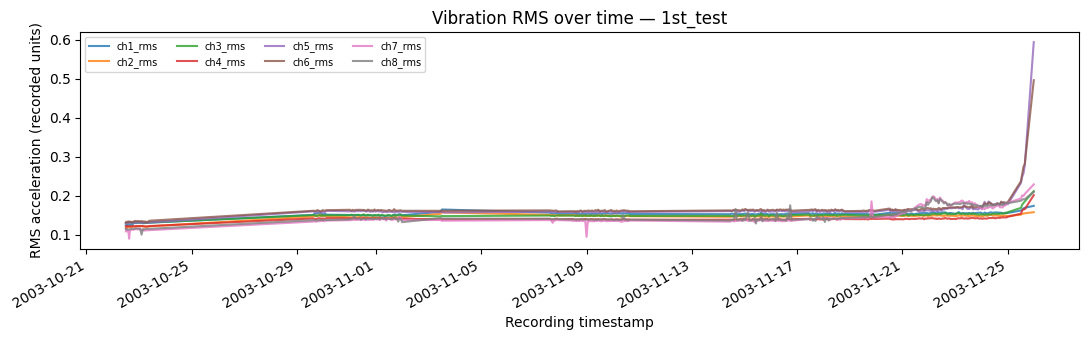

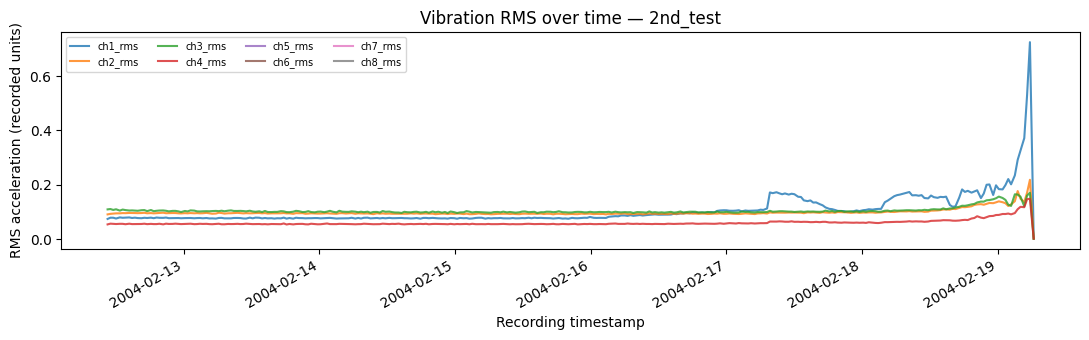

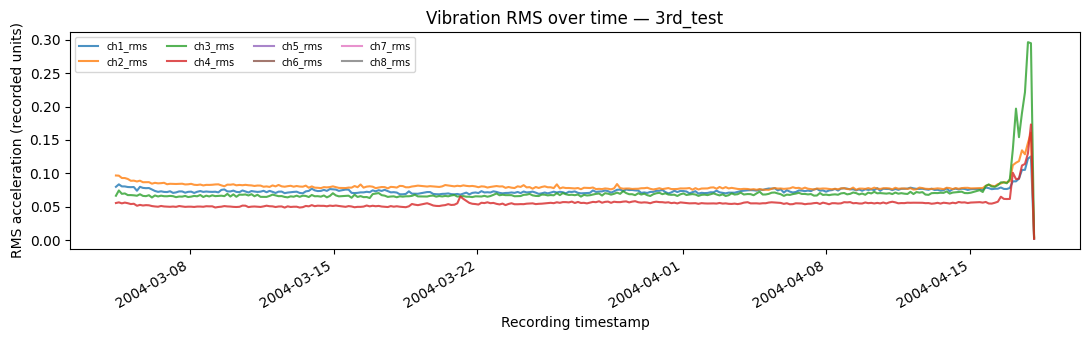

In [ ]:
summary=feat.groupby('run').agg(n=('timestamp','size'),start=('timestamp','min'),end=('timestamp','max'))
display(summary)
for run,g in feat.groupby('run'):
    g=g.sort_values('timestamp')
    cols=[c for c in g.columns if c.endswith('_rms')]
    fig,ax=plt.subplots(figsize=(11,3.5))
    for c in cols:ax.plot(g.timestamp,g[c],label=c,alpha=.8)
    ax.set(title=f'Vibration RMS over time — {run}',ylabel='RMS acceleration (recorded units)',xlabel='Recording timestamp')
    ax.legend(ncol=4,fontsize=7);fig.autofmt_xdate();fig.tight_layout()
    fig.savefig(FIGURES/(re.sub(r'[^a-zA-Z0-9_-]','_',run)+'_rms.png'),dpi=140)
    plt.show()

## 7. Fit unsupervised anomaly-detection models — Clayton Roy

**Objective:** Compare two ways of identifying vibration feature patterns that differ from an early-run reference period.

**Reference design:** For each run, sort recordings chronologically. Treat the earliest **20%** as a *presumed* baseline, not verified healthy observations. Fit missing-value imputation and robust scaling **only on this reference period** to reduce future-data leakage.

**Models:**
1. **Isolation Forest:** An ensemble that assigns higher anomaly scores to unusual feature combinations. The notebook negates `score_samples` so that larger scores indicate more anomalous behavior.
2. **PCA reconstruction error:** Fit a lower-dimensional representation on the reference period, reconstruct all observations, and use mean squared reconstruction error as the anomaly score.

For each model, set an alert threshold at the **99th percentile of its own reference-period scores**. The threshold is heuristic, not calibrated to a known fault rate. Models are fitted separately for each run.

**Expected outputs:** Saved model bundles in `models/`, anomaly scores in `results/anomaly_scores.csv`, and a per-run model manifest.

**Limitations:** Reference-period contamination, correlated recordings, and a small number of run-to-failure experiments can affect reliability. The threshold is not evidence of a 1% real-world false-alarm rate.


In [ ]:
# Processed feature file.
PROC_DATA_PATH = ('/content/drive/MyDrive/CS505_Predictive_Maintenance_Project/data/processed/ims_features_limit_300.csv')

# Fraction of each run, used AS the reference period.
REF_FRAC = 0.20

# Fraction of the reference period, held for threshholds.
CAL_FRAC = 0.25

# Quantile of held-out reference scores.
THRESH_Q = 0.99

# Retain 95% of variation in training files.
PCA_VAR = .95

# Random seed for repeatable Isolation Forest results.
SEED = 42

# Dictionary for each run with association between channel and bearing.
RUNS = {
        'Test_1': ('set_1', {1: [1,2], 2: [3,4], 3: [5,6], 4: [7,8]}),
        'Test_2': ('set_2', {1: [1], 2: [2], 3: [3], 4: [4]}),
        'Test_3': ('set_3', {1: [1], 2: [2], 3: [3], 4: [4]}),
}


In [ ]:
# Read file and set timestamp column to dates.
RAW = pd.read_csv(PROC_DATA_PATH, parse_dates=["timestamp"])

RAW.head()

# Dicitonary to map run names.
features = {}

# Loop through each run.
for run_label, (name, bearings) in RUNS.items():

  part = RAW[RAW.run == run_label]

  tables = []

  # Loop through each bearing and its channel whilst creating new tables for each bearing.
  for b, channels in bearings.items():

    t = pd.DataFrame({'time': part.timestamp, 'bearing': b, 'file': part.source_path.map(lambda p: Path(p).name)})

    # Loop to copy and rename columns.
    for k, c in enumerate(channels, start = 1):

      # Copies per feature 1 by 1.
      for col in [x for x in RAW.columns if x.startswith(f'ch{c}_')]:

        t[f'ch{k}_' + col.split('_', 1)[1]] = part[col]

    tables.append(t)

# Stack 4 bearings into one table for the run.
features[name] = pd.concat(tables, ignore_index = True)

features[name].head()



,time,bearing,file,ch1_rms,ch1_std,ch1_ptp,ch1_crest,ch1_skew,ch1_kurtosis,ch1_spectral_centroid,ch2_rms,ch2_std,ch2_ptp,ch2_crest,ch2_skew,ch2_kurtosis,ch2_spectral_centroid


## 8. Visualize anomaly scores over time — Aven Pacha Pinto

**Objective:** Examine when each model's score departs from its early-run reference distribution.

For each run and model, plot the anomaly score against the recording timestamp, draw the reference-derived threshold, and shade the presumed baseline interval.

**How to read the figures:** A score above the dashed threshold is an **algorithmic alert**. It does not independently establish a fault or predict failure time. Compare the timing, magnitude, and persistence of alerts across methods.

**Expected output:** One figure per run–model combination saved in `results/figures/`.

**Discussion prompts:** Do both models highlight similar intervals? Are alerts isolated spikes or sustained shifts? Could changes reflect operating conditions rather than damage?


## 9. Compare anomaly-alert behavior — Aven Pacha Pinto

**Objective:** Summarize model outputs on observations **after** the presumed reference period.

The comparison table reports the number of evaluated recordings, the fraction flagged as alerts, and median and maximum anomaly scores for each run and model.

**Interpretation:** Alert rate is a descriptive quantity: $\text{alert rate}=\frac{\text{flagged recordings}}{\text{evaluated recordings}}$. It is **not** precision, recall, F1, or classification accuracy because observation-level verified labels are not supplied by this workflow. Raw score magnitudes are also not directly comparable across Isolation Forest and PCA because their scales differ.

**Expected output:** `results/descriptive_model_comparison.csv` and an on-screen comparison table.

**Possible extension:** If documented fault-event timing or reliable annotations are obtained, define and justify a separate event-level evaluation before reporting detection performance.


## 10. Save experiment settings and reproducibility information — Member 5

**Objective:** Record enough information for another teammate to identify the source data and rerun the experiment.

The experiment manifest records the dataset source page, selected archive and checksum, assumed sample rate, random seed, per-run sampling limit, baseline fraction, evaluation type, and run-level model information.

**Expected output:** `results/experiment_manifest.json` alongside the trained models, feature CSV, and figures.

**Reproducibility checklist:** Confirm that source ZIP, notebook version, preprocessing settings, and output files match; document library versions before final submission; keep the original dataset unchanged. Do not upload the full dataset to GitHub unless its distribution terms and repository size make that appropriate—link to NASA instead.


## 11. Interpretation, limitations, and final project integration — Member 6

### What the results can support
The notebook can describe changes in vibration statistics over a bearing run and compare the **behavior** of Isolation Forest and PCA anomaly scores under a common chronological reference-period protocol.

### What the results cannot establish without additional evidence
- No verified observation-level failure labels are used, so **accuracy, precision, recall, F1, and ROC-AUC must not be claimed**.
- A high anomaly score does not prove a bearing failure or establish advance warning time.
- The earliest 20% of a run is **assumed** to be a baseline; this is not independently validated as healthy.
- The 300-file setting is a sampled exploratory run unless changed to `None`.
- Results from a small set of laboratory run-to-failure experiments may not generalize to deployed industrial equipment.

### Team deliverables
Use the actual generated plots and comparison table in the report and presentation. Cite the NASA/University of Cincinnati dataset and any research or software sources relied upon. Include a link to the team's **own** GitHub repository in the final report, as required by the professor. Clearly distinguish this team's code and experiments from the original dataset authors' work.

### Final quality check
Confirm that Sections 1–10 execute in sequence on the shared dataset, that figures and CSVs are saved, and that the paper describes **observed results rather than expected outcomes**. Each member should review the combined notebook and explain their assigned contribution during the presentation.
